In [13]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [14]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical summary:")
df.describe()

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [15]:
# Display actual flower labels
print(iris.target_names)

# Count each flower species
print(pd.Series(iris.target).value_counts())

['setosa' 'versicolor' 'virginica']
0    50
1    50
2    50
Name: count, dtype: int64


In [16]:
from sklearn.preprocessing import StandardScaler

# Select features
X = df

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized dataset:")
print(X_scaled[:5])

Standardized dataset:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [17]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Train the model
kmeans.fit(X_scaled)

# Predict clusters
clusters = kmeans.labels_

# Add cluster labels to dataset
df['Cluster'] = clusters

# Display first 10 rows
df.head(10)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


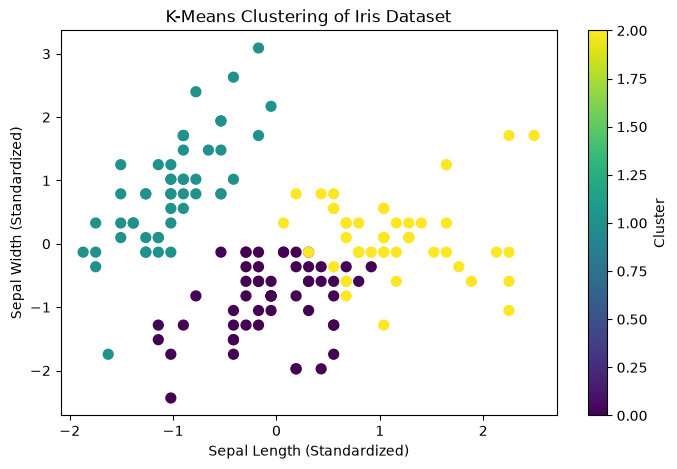

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.xlabel('Sepal Length (Standardized)')
plt.ylabel('Sepal Width (Standardized)')
plt.title('K-Means Clustering of Iris Dataset')
plt.colorbar(label='Cluster')

plt.show()

In [19]:
# Add actual species labels
df['Actual Species'] = iris.target

# Display actual and predicted clusters
comparison = df[['Cluster', 'Actual Species']]

print(comparison.head(15))

    Cluster  Actual Species
0         1               0
1         1               0
2         1               0
3         1               0
4         1               0
5         1               0
6         1               0
7         1               0
8         1               0
9         1               0
10        1               0
11        1               0
12        1               0
13        1               0
14        1               0


In [20]:
print("Cluster distribution:")
print(df['Cluster'].value_counts().sort_index())

Cluster distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


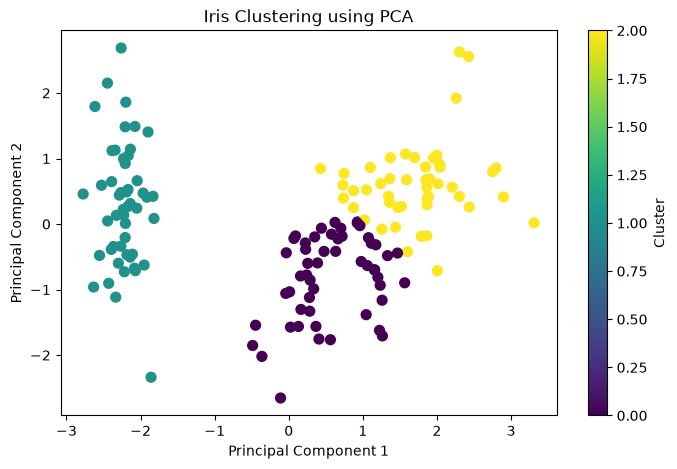

In [21]:
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Iris Clustering using PCA')
plt.colorbar(label='Cluster')

plt.show()

In [22]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

print("Total variance retained:",
      sum(pca.explained_variance_ratio_) * 100, "%")

Explained variance ratio: [0.72962445 0.22850762]
Total variance retained: 95.81320720000161 %


In [23]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.45994823920518646


In [24]:
print("IRIS FLOWER CLUSTERING PROJECT")
print("--------------------------------")

print("Total Samples:", len(df))
print("Total Features:", 4)
print("Number of Clusters:", 3)
print("Algorithm Used: K-Means")
print("Dimensionality Reduction: PCA")
print("Silhouette Score:", round(score, 3))

print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

IRIS FLOWER CLUSTERING PROJECT
--------------------------------
Total Samples: 150
Total Features: 4
Number of Clusters: 3
Algorithm Used: K-Means
Dimensionality Reduction: PCA
Silhouette Score: 0.46

Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64
